# Teorema de Bayes con letras 
### Juan Esteban Martinez Herrera - Juan David Cuartas

Métodos de Machine Learning en Ciencias e Ingenierías · 2026A

## Descripción

Modelo de lenguaje a nivel de carácter basado en probabilidades condicionales. Se estima $P(c_{n+1}\mid c_n)$ por conteo sobre un corpus y se utiliza para predicción (ej. 2), generación (ej. 3), inversión mediante el teorema de Bayes (ej. 4) y análisis espectral (ej. 5). La sección 6 es una extensión con contexto de orden $k$.

## Dependencias

| Paquete | Versión mínima | Uso |
|---|---|---|
| Python | 3.10 | — |
| numpy | 1.26 | conteos, SVD, valores propios |
| pandas | 2.1 | tablas de resultados |
| matplotlib | 3.8 | gráficas |
| seaborn | 0.13 | mapas de calor |
| ipykernel | — | ejecución del notebook |

Instalación: `pip install -r requirements.txt`. La fuente de las figuras es Arial; si no está instalada se usa Liberation Sans o DejaVu Sans.

In [1]:
import re, os, sys, math, html, random, zipfile, textwrap, posixpath, unicodedata
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from urllib.parse import unquote

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager

disponibles = {f.name for f in font_manager.fontManager.ttflist}
FUENTE = next((f for f in ("Arial", "Liberation Sans", "DejaVu Sans") if f in disponibles), "sans-serif")
sns.set_theme(style="whitegrid", context="notebook", font=FUENTE)
plt.rcParams["figure.dpi"] = 110
SEMILLA = 7

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | seaborn {sns.__version__} | fuente: {FUENTE}")

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | matplotlib 3.11.2 | seaborn 0.13.2 | fuente: Liberation Sans


## Corpus

*Crime and Punishment* (F. Dostoyevsky, trad. C. Garnett), formato `.epub`. Las páginas se leen en el orden del *spine* del EPUB, se descartan los documentos de navegación y, si existen, el encabezado y el pie legales de Project Gutenberg.

In [2]:
RUTA_LIBRO = "crimen_y_castigo.epub"      # .epub o .txt, en la misma carpeta que el notebook

def leer_epub(ruta):
    """Texto de un EPUB en orden de lectura (spine), sin documentos de navegación."""
    with zipfile.ZipFile(ruta) as z:
        nombres = z.namelist()
        paginas_html = sorted(n for n in nombres if n.lower().endswith((".xhtml", ".html", ".htm")))
        try:
            opf = next(n for n in nombres if n.lower().endswith(".opf"))
            raiz = ET.fromstring(z.read(opf))
            ns = {"o": "http://www.idpf.org/2007/opf"}
            items = {i.get("id"): i for i in raiz.findall(".//o:manifest/o:item", ns)}
            orden = []
            for ref in raiz.findall(".//o:spine/o:itemref", ns):
                it = items[ref.get("idref")]
                if "nav" in (it.get("properties") or ""):
                    continue
                orden.append(posixpath.normpath(posixpath.join(posixpath.dirname(opf), unquote(it.get("href")))))
            orden = [n for n in orden if n in nombres] or paginas_html
        except (StopIteration, KeyError, ET.ParseError):
            orden = paginas_html
        textos = []
        for n in orden:
            h = z.read(n).decode("utf-8", errors="ignore")
            h = re.sub(r"(?is)<(script|style).*?</\1>", " ", h)    # scripts y estilos
            h = re.sub(r"(?s)<[^>]+>", " ", h)                     # etiquetas HTML
            textos.append(html.unescape(h))
    return "\n".join(textos)

def leer_libro(ruta):
    if ruta.lower().endswith(".epub"):
        return leer_epub(ruta)
    with open(ruta, encoding="utf-8-sig", errors="ignore") as f:
        return f.read()

def recortar_gutenberg(texto):
    ini = re.search(r"\*\*\*\s*START OF.{0,200}?\*\*\*", texto, re.I | re.S)
    if ini:
        texto = texto[ini.end():]
    fin = re.search(r"\*\*\*\s*END OF.{0,200}?\*\*\*", texto, re.I | re.S)
    return texto[:fin.start()] if fin else texto

if not os.path.exists(RUTA_LIBRO):
    cercanos = [f for f in os.listdir(".") if f.lower().endswith((".epub", ".txt"))]
    raise FileNotFoundError(f"No se encuentra '{RUTA_LIBRO}'. Archivos .epub/.txt en la carpeta: {cercanos}")

crudo = re.sub(r"\s+", " ", recortar_gutenberg(leer_libro(RUTA_LIBRO))).strip()
print(f"{len(crudo):,} caracteres. Inicio del texto:\n")
print(textwrap.fill(crudo[:300], 100))

1,130,925 caracteres. Inicio del texto:

CRIME AND PUNISHMENT By Fyodor Dostoevsky Translated By Constance Garnett CONTENTS TRANSLATOR’S
PREFACE CRIME AND PUNISHMENT PART I CHAPTER I CHAPTER II CHAPTER III CHAPTER IV CHAPTER V CHAPTER VI
CHAPTER VII PART II CHAPTER I CHAPTER II CHAPTER III CHAPTER IV CHAPTER V CHAPTER VI CHAPTER VII
PART I


## Preprocesamiento

Minúsculas, eliminación de diacríticos y de rótulos de capítulo (`CHAPTER IV`, `PART II`…); todo carácter no alfabético se reemplaza por espacio. El alfabeto $\Sigma$ está formado por los símbolos resultantes. El espacio se denota «_» en tablas y figuras.

In [3]:
def limpiar(texto):
    t = re.sub(r"\b(?:CHAPTER|PART|BOOK|EPILOGUE)\s+[IVXLC]+\b", " ", texto)   # rótulos de capítulo
    t = t.lower().replace("ñ", "\0")                                          # protege la ñ
    t = unicodedata.normalize("NFD", t)
    t = "".join(c for c in t if unicodedata.category(c) != "Mn")              # elimina diacríticos
    t = t.replace("\0", "ñ")
    t = re.sub(r"[^a-zñ]+", " ", t)                                           # no alfabético -> espacio
    return t.strip()

muestra = crudo[2000:2140]
print("ANTES  :", muestra)
print("DESPUÉS:", limpiar(muestra))

TEXTO = limpiar(crudo)
ALFABETO = [" "] + sorted(set(TEXTO) - {" "})            # índice 0: espacio
N = len(ALFABETO)
IDX = {c: i for i, c in enumerate(ALFABETO)}             # símbolo -> índice de fila/columna
ETIQ = ["_" if c == " " else c for c in ALFABETO]        # etiquetas para tablas y figuras

print(f"\n|Σ| = {N}: {''.join(ETIQ)}")
print(f"Texto limpio: {len(TEXTO):,} símbolos")

ANTES  :  he was with twenty-one others taken out to the Semyonovsky Square to be shot. Writing to his brother Mihail, Dostoevsky says: “They snapped
DESPUÉS: he was with twenty one others taken out to the semyonovsky square to be shot writing to his brother mihail dostoevsky says they snapped



|Σ| = 27: _abcdefghijklmnopqrstuvwxyz
Texto limpio: 1,082,694 símbolos


### Frecuencias marginales

Distribución $p(c)$ del corpus, usada como referencia en las secciones siguientes.

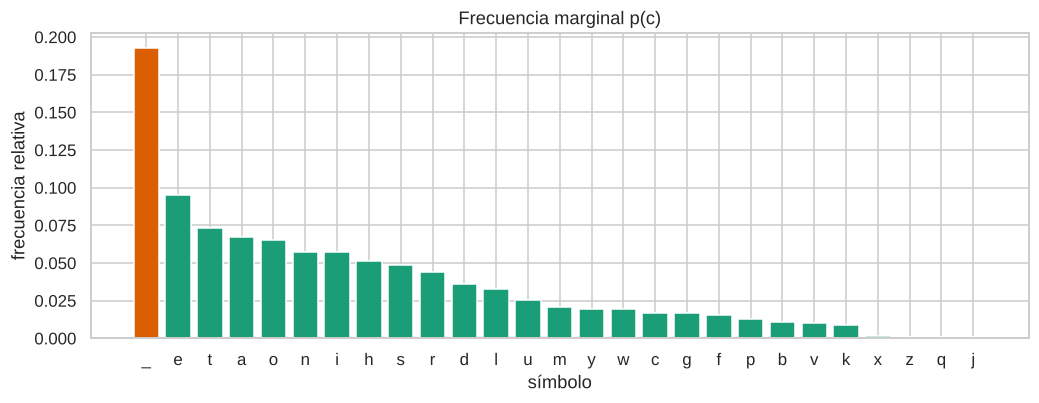

In [4]:
V = np.array([IDX[c] for c in TEXTO])                    # corpus codificado como índices
FREC = np.bincount(V, minlength=N) / len(V)              # p(c)

orden = np.argsort(FREC)[::-1]
colores = ["#d95f02" if ALFABETO[j] == " " else "#1b9e77" for j in orden]

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar([ETIQ[j] for j in orden], FREC[orden], color=colores)
ax.set(title="Frecuencia marginal p(c)", xlabel="símbolo", ylabel="frecuencia relativa")
plt.show()

## 1. Matriz de transición

Sea $C_{ab}$ el número de veces que el símbolo $b$ sigue inmediatamente a $a$. Entonces

$$P(c_{n+1}=b\mid c_n=a)=\frac{C_{ab}}{\sum_{b'}C_{ab'}}$$

Ilustración con la cadena «abracadabra».

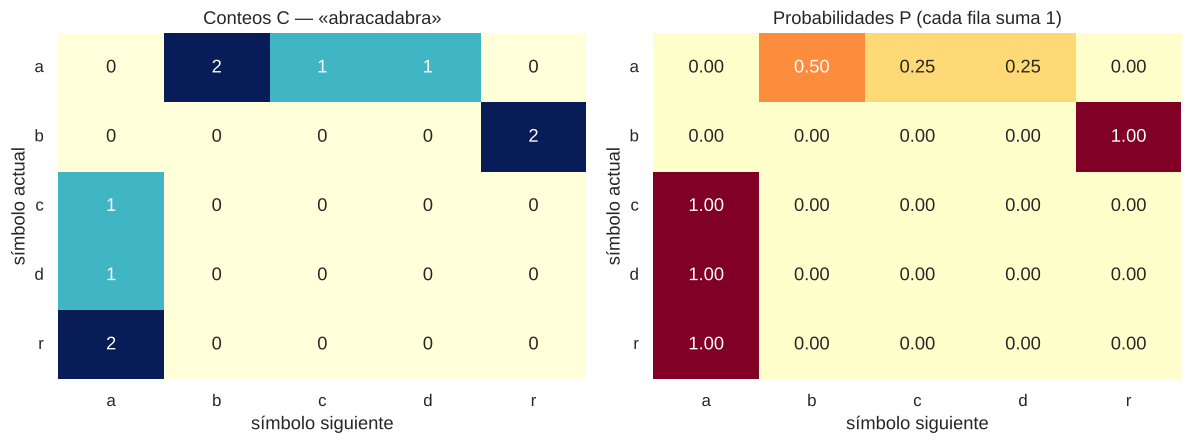

In [5]:
def matriz_conteo(texto, alfabeto=ALFABETO):
    """C[a, b]: número de veces que b sigue a a (fila = actual, columna = siguiente)."""
    idx = {c: i for i, c in enumerate(alfabeto)}
    v = np.array([idx[c] for c in texto if c in idx])
    M = np.zeros((len(alfabeto), len(alfabeto)))
    np.add.at(M, (v[:-1], v[1:]), 1)
    return M

def a_probabilidad(M):
    """Normalización por filas."""
    totales = M.sum(axis=1, keepdims=True)
    return np.divide(M, totales, out=np.zeros_like(M), where=totales > 0)

frase = "abracadabra"
alf_toy = sorted(set(frase))
M_toy = matriz_conteo(frase, alf_toy)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(M_toy, annot=True, fmt=".0f", cmap="YlGnBu", cbar=False, ax=axes[0],
            xticklabels=alf_toy, yticklabels=alf_toy)
axes[0].set(title=f"Conteos C — «{frase}»", xlabel="símbolo siguiente", ylabel="símbolo actual")
sns.heatmap(a_probabilidad(M_toy), annot=True, fmt=".2f", cmap="YlOrRd", cbar=False, ax=axes[1],
            xticklabels=alf_toy, yticklabels=alf_toy)
axes[1].set(title="Probabilidades P (cada fila suma 1)", xlabel="símbolo siguiente", ylabel="símbolo actual")
for ax in axes: plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

Matriz del corpus: conteos (escala logarítmica) y probabilidades.

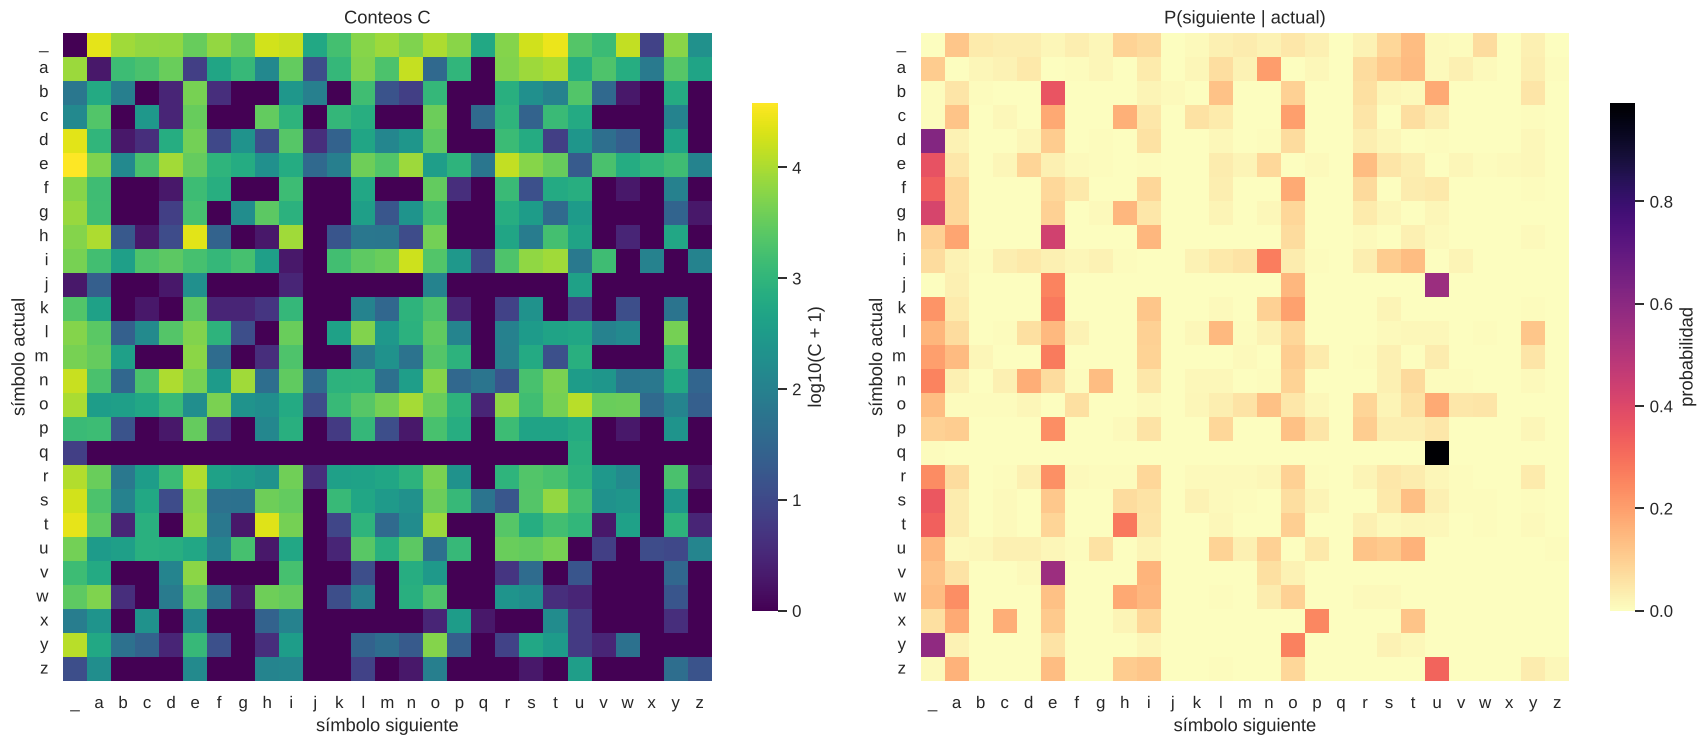

Filas normalizadas: True


In [6]:
CONT = matriz_conteo(TEXTO)       # C
P = a_probabilidad(CONT)          # P[a, b] = P(siguiente = b | actual = a)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(np.log10(CONT + 1), cmap="viridis", square=True, ax=axes[0],
            xticklabels=ETIQ, yticklabels=ETIQ, cbar_kws={"label": "log10(C + 1)", "shrink": .7})
axes[0].set(title="Conteos C", xlabel="símbolo siguiente", ylabel="símbolo actual")
sns.heatmap(P, cmap="magma_r", square=True, ax=axes[1],
            xticklabels=ETIQ, yticklabels=ETIQ, cbar_kws={"label": "probabilidad", "shrink": .7})
axes[1].set(title="P(siguiente | actual)", xlabel="símbolo siguiente", ylabel="símbolo actual")
for ax in axes: plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

print("Filas normalizadas:", np.allclose(P.sum(axis=1), 1))

### Distribuciones condicionales (filas de $P$)

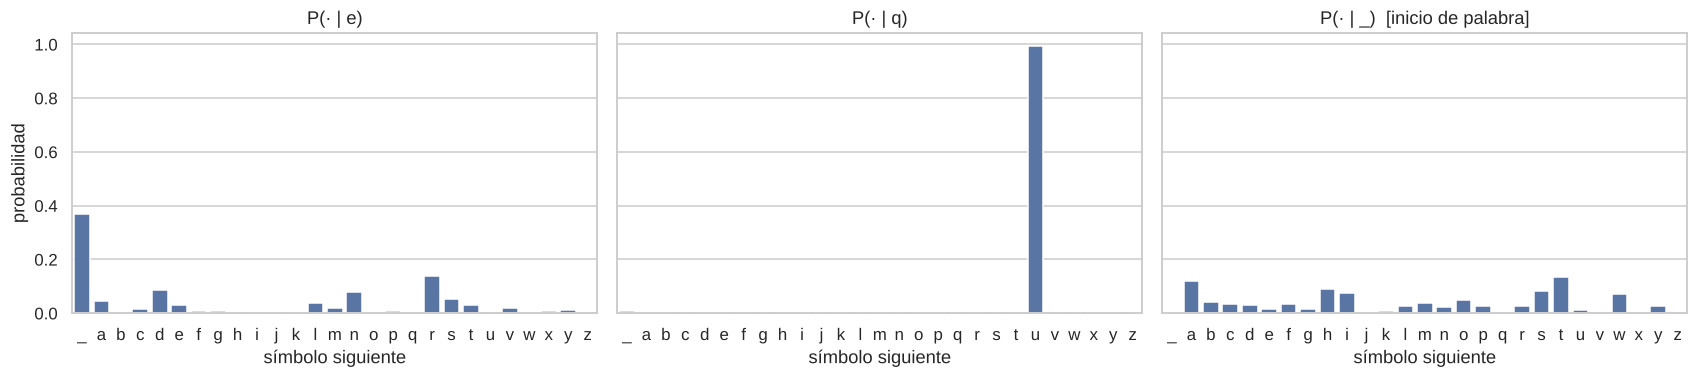

In [7]:
elegidas = [c for c in ["e", "q", " "] if c in IDX]

fig, axes = plt.subplots(1, len(elegidas), figsize=(5.2 * len(elegidas), 3.6), sharey=True)
for ax, c in zip(np.atleast_1d(axes), elegidas):
    sns.barplot(x=ETIQ, y=P[IDX[c]], color="#4c72b0", ax=ax)
    ax.set(title="P(· | _)  [inicio de palabra]" if c == " " else f"P(· | {c})",
           xlabel="símbolo siguiente", ylabel="probabilidad")
plt.tight_layout(); plt.show()

## 2. Agente predictor

Dado el símbolo actual $a$, se proponen los $k=2$ símbolos con mayor $P(\cdot\mid a)$.

Evaluación: estimación de $P$ con el 90 % inicial del corpus y prueba con el 10 % final. Líneas base: selección aleatoria y los $k$ símbolos más frecuentes según $p(c)$.

In [8]:
def sugerir(letra, k=2, matriz=P):
    """k símbolos más probables después de `letra`, con su probabilidad."""
    fila = matriz[IDX[letra]]
    mejores = np.argsort(fila)[::-1][:k]
    return [(ALFABETO[j], fila[j]) for j in mejores]

etiqueta = lambda c: "_" if c == " " else c

frase = "he walked slowly down the street"
filas = []
for actual, real in zip(frase[:-1], frase[1:]):
    if actual not in IDX:
        continue
    s = sugerir(actual)
    filas.append({
        "actual": etiqueta(actual),
        "sugerencia 1": f"{etiqueta(s[0][0])} ({s[0][1]:.0%})",
        "sugerencia 2": f"{etiqueta(s[1][0])} ({s[1][1]:.0%})",
        "siguiente real": etiqueta(real),
        "acierto": "sí" if real in [x for x, _ in s] else "no",
    })
demo = pd.DataFrame(filas)
print(f"Acierto top-2 en la frase: {(demo['acierto'] == 'sí').mean():.0%}")
demo

Acierto top-2 en la frase: 42%


,actual,sugerencia 1,sugerencia 2,siguiente real,acierto
0,h,e (43%),a (19%),e,sí
1,e,_ (37%),r (14%),_,sí
2,_,t (14%),a (12%),w,no
3,w,a (24%),h (18%),a,sí
4,a,n (20%),t (14%),l,no
5,l,_ (15%),l (15%),k,no
6,k,e (28%),_ (22%),e,sí
7,e,_ (37%),r (14%),d,no
8,d,_ (62%),e (11%),_,sí
9,_,t (14%),a (12%),s,no


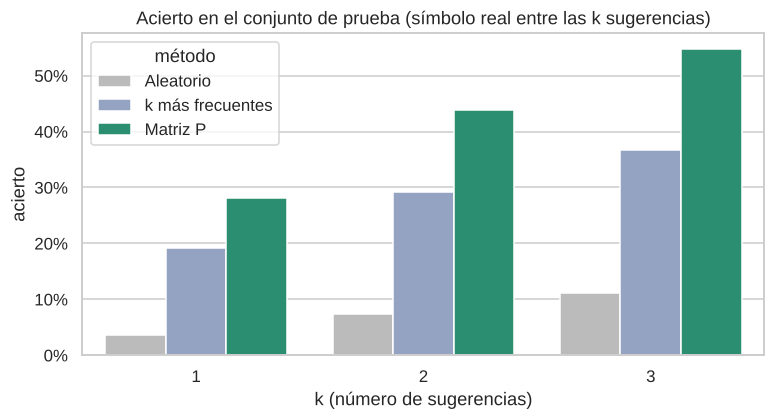

In [9]:
corte = int(0.9 * len(V))
P_entrenada = a_probabilidad(matriz_conteo(TEXTO[:corte]))
actual, siguiente = V[corte:-1], V[corte + 1:]                 # pares del 10 % de prueba

ranking = np.argsort(-P_entrenada[actual], axis=1)
mas_comunes = np.argsort(-FREC)

resultados = []
for k in (1, 2, 3):
    resultados += [
        {"k": k, "método": "Aleatorio", "acierto": k / N},
        {"k": k, "método": "k más frecuentes", "acierto": np.isin(siguiente, mas_comunes[:k]).mean()},
        {"k": k, "método": "Matriz P", "acierto": (ranking[:, :k] == siguiente[:, None]).any(axis=1).mean()},
    ]

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=pd.DataFrame(resultados), x="k", y="acierto", hue="método",
            palette=["#bbbbbb", "#8da0cb", "#1b9e77"], ax=ax)
ax.set(title="Acierto en el conjunto de prueba (símbolo real entre las k sugerencias)",
       xlabel="k (número de sugerencias)", ylabel="acierto")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
plt.show()

## 3. Generación de texto

Cadena de Markov de primer orden: $c_1$ aleatorio y $c_{n+1}\sim P(\cdot\mid c_n)$ hasta $n=200$. Referencias: (0a) símbolos equiprobables; (0b) símbolos i.i.d. con distribución $p(c)$.

In [10]:
def generar(matriz, n=200, rng=None):
    """Genera n símbolos: c_{n+1} se sortea con la fila de c_n."""
    rng = rng or np.random.default_rng(SEMILLA)
    acumulada = matriz.cumsum(axis=1)
    sorteos = rng.random(n)
    actual = rng.integers(1, N)                           # símbolo inicial aleatorio (no espacio)
    salida = [actual]
    for u in sorteos[1:]:
        actual = min(np.searchsorted(acumulada[actual], u, side="right"), N - 1)
        salida.append(actual)
    return "".join(ALFABETO[j] for j in salida)

def generar_sin_memoria(n, probs, rng):
    return "".join(rng.choice(ALFABETO, size=n, p=probs))

rng = np.random.default_rng(SEMILLA)
t_uniforme  = generar_sin_memoria(200, np.full(N, 1 / N), rng)
t_frecuente = generar_sin_memoria(200, FREC, rng)
t_markov    = generar(P, 200, rng)

for nombre, t in [("0a · equiprobable", t_uniforme),
                  ("0b · i.i.d. según p(c)", t_frecuente),
                  ("Primer orden · P(siguiente | actual)", t_markov)]:
    print(f"[{nombre}]\n{textwrap.fill(t, 90)}\n")

[0a · equiprobable]
pxtfhw vulhgflmnzupzedpa mlxpmmf erei
vdgwmvqtbnmwipajhdvjzopqrdkfjbzerhwqcvyxoceyndwqojkfawlnht j czqknwiorintxdy tuckv
pumsfeidiyoigylzmnxtokwkxaknyfurspzhjeaexvcplpqhylpqdaktvscxuwnxa  ffeoaodr hyn

[0b · i.i.d. según p(c)]
snm l rwt ed nrdtr rtalnm nnsseott  nakueahn e nseeiaaeh pld r    tbdsm gteo orsne ip bipt
rnoyusren rqogef sieioeste ry ost  y  lgp tar h ddoh yttaea  i  th nbiciniert   xuawaiht
dl ahtrsrosood p tl

[Primer orden · P(siguiente | actual)]
st m whikothreastas nl s weashianet ine of t isopremothefasanke teroni ithengece
hezheapute ung t m isthind d sp sse s renanemay ha isof hintheromane in be w ced je t
pecodour sis wo h tryaslkord ason



### Similitud con el idioma

Fracción de «palabras» generadas (20 000 símbolos) que pertenecen al vocabulario del corpus, y longitud media de palabra.

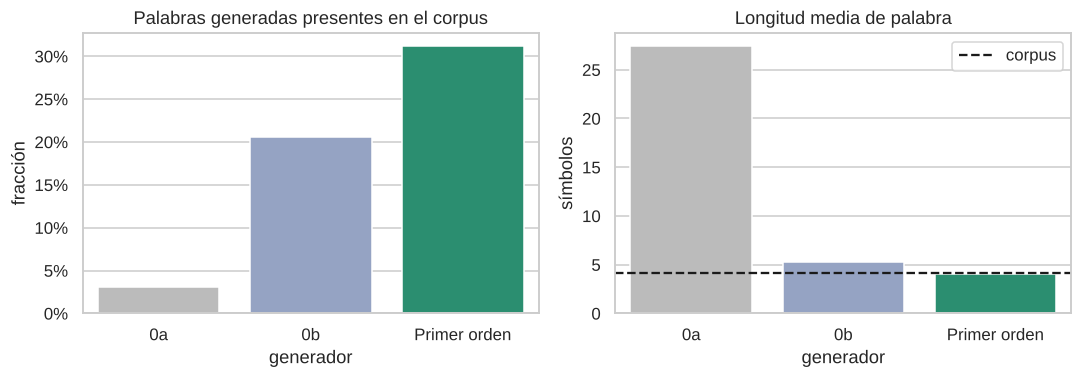

In [11]:
rng = np.random.default_rng(SEMILLA)
largos = {
    "0a": generar_sin_memoria(20_000, np.full(N, 1 / N), rng),
    "0b": generar_sin_memoria(20_000, FREC, rng),
    "Primer orden": generar(P, 20_000, rng),
}
VOCAB = set(TEXTO.split())
porcentaje = {k: np.mean([p in VOCAB for p in t.split()]) for k, t in largos.items()}
long_media = {k: np.mean([len(p) for p in t.split()]) for k, t in largos.items()}
paleta3 = ["#bbbbbb", "#8da0cb", "#1b9e77"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
sns.barplot(x=list(porcentaje), y=list(porcentaje.values()), hue=list(porcentaje), palette=paleta3, legend=False, ax=axes[0])
axes[0].set(title="Palabras generadas presentes en el corpus", xlabel="generador", ylabel="fracción")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
sns.barplot(x=list(long_media), y=list(long_media.values()), hue=list(long_media), palette=paleta3, legend=False, ax=axes[1])
axes[1].axhline(np.mean([len(p) for p in TEXTO.split()]), color="k", ls="--", label="corpus")
axes[1].set(title="Longitud media de palabra", xlabel="generador", ylabel="símbolos")
axes[1].legend()
plt.tight_layout(); plt.show()

### Fidelidad de las frecuencias marginales

Comparación con $p(c)$ para $L=200$ y $L=10^5$, y distancia de variación total $\mathrm{TV}=\tfrac12\sum_c\lvert p_{\text{gen}}(c)-p(c)\rvert$ en función de $L$ (promedio sobre réplicas).

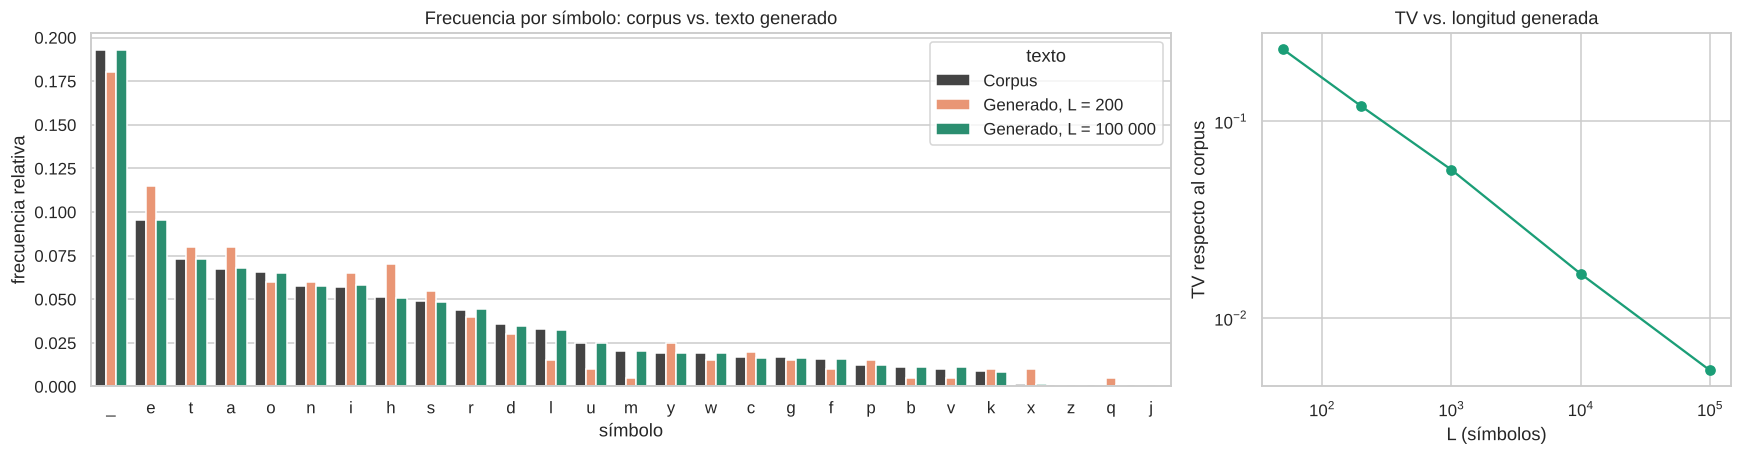

Pendiente log-log de TV(L): -0.50


In [12]:
def frecuencias(texto):
    v = [IDX[c] for c in texto]
    return np.bincount(v, minlength=N) / len(v)

rng = np.random.default_rng(SEMILLA)
f200  = frecuencias(generar(P, 200, rng))
f100k = frecuencias(generar(P, 100_000, rng))

orden = np.argsort(FREC)[::-1]
tabla = pd.DataFrame({
    "símbolo": [ETIQ[j] for j in orden] * 3,
    "frecuencia": np.concatenate([FREC[orden], f200[orden], f100k[orden]]),
    "texto": ["Corpus"] * N + ["Generado, L = 200"] * N + ["Generado, L = 100 000"] * N,
})

tamanos = [50, 200, 1_000, 10_000, 100_000]
errores = []
for L in tamanos:
    repeticiones = 20 if L <= 10_000 else 4
    e = [0.5 * np.abs(frecuencias(generar(P, L, np.random.default_rng(s))) - FREC).sum() for s in range(repeticiones)]
    errores.append(np.mean(e))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.3), gridspec_kw={"width_ratios": [2.3, 1]})
sns.barplot(data=tabla, x="símbolo", y="frecuencia", hue="texto", palette=["#444444", "#fc8d62", "#1b9e77"], ax=axes[0])
axes[0].set(title="Frecuencia por símbolo: corpus vs. texto generado", ylabel="frecuencia relativa")
axes[1].loglog(tamanos, errores, "o-", color="#1b9e77")
axes[1].set(title="TV vs. longitud generada", xlabel="L (símbolos)", ylabel="TV respecto al corpus")
plt.tight_layout(); plt.show()

print(f"Pendiente log-log de TV(L): {np.polyfit(np.log(tamanos), np.log(errores), 1)[0]:.2f}")

### Fidelidad de las transiciones

Elementos de $P$ estimados sobre 100 000 símbolos generados frente a los del corpus; la diagonal indica coincidencia.

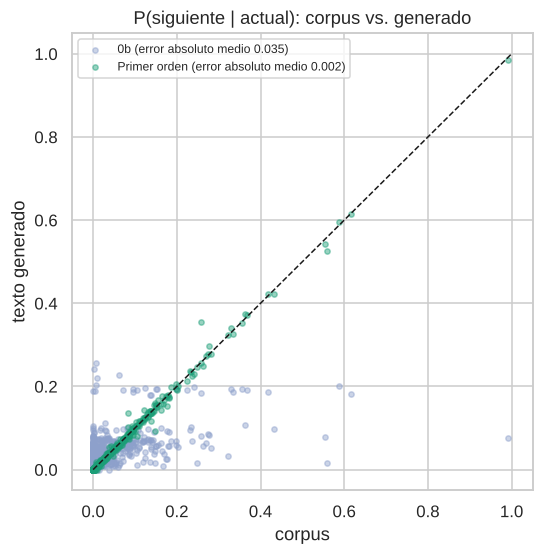

In [13]:
rng = np.random.default_rng(SEMILLA)
P_matriz  = a_probabilidad(matriz_conteo(generar(P, 100_000, rng)))
P_sin_mem = a_probabilidad(matriz_conteo(generar_sin_memoria(100_000, FREC, rng)))

fig, ax = plt.subplots(figsize=(5.4, 5.4))
ax.scatter(P.ravel(), P_sin_mem.ravel(), s=12, alpha=.45, color="#8da0cb",
           label=f"0b (error absoluto medio {np.abs(P - P_sin_mem).mean():.3f})")
ax.scatter(P.ravel(), P_matriz.ravel(), s=12, alpha=.45, color="#1b9e77",
           label=f"Primer orden (error absoluto medio {np.abs(P - P_matriz).mean():.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(title="P(siguiente | actual): corpus vs. generado", xlabel="corpus", ylabel="texto generado")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Observaciones**

- $\mathrm{TV}$ decrece con $L$: a $L=200$ el error de muestreo de las frecuencias es apreciable.
- El generador de primer orden reproduce $p(c)$ y las transiciones; el 0b reproduce solo $p(c)$.
- El texto generado conserva estructura local (digramas), pero un contexto de un solo símbolo no garantiza palabras válidas (sección 6).

## 4. Teorema de Bayes

$$P(A\mid B)=\frac{P(B\mid A)\,P(A)}{P(B)}$$

Con $A=c_n$ y $B=c_{n+1}$: $P(B\mid A)$ es la matriz $P$; $P(A)=\sum_b J_{ab}$ y $P(B)=\sum_a J_{ab}$, donde $J=C/\sum C$ es la distribución conjunta de pares. Se compara $P(A\mid B)$ obtenida normalizando las columnas de $J$ con la obtenida mediante Bayes.

Validación previa con la tabla de contingencia de la lectura (Ejemplo 1): $P(H\mid R)$.

In [14]:
fiesta = pd.DataFrame([[5, 35], [20, 40]], index=["Hombre", "Mujer"], columns=["Rosa", "Otros"])
total = fiesta.values.sum()

P_H = fiesta.loc["Hombre"].sum() / total
P_R = fiesta["Rosa"].sum() / total
P_R_dado_H = fiesta.loc["Hombre", "Rosa"] / fiesta.loc["Hombre"].sum()

directo   = fiesta.loc["Hombre", "Rosa"] / fiesta["Rosa"].sum()
por_bayes = P_R_dado_H * P_H / P_R

print(fiesta, end="\n\n")
print(f"Conteo directo : P(H|R) = {directo:.3f}")
print(f"Bayes          : P(H|R) = {P_R_dado_H:.3f} · {P_H:.2f} / {P_R:.2f} = {por_bayes:.3f}")

        Rosa  Otros
Hombre     5     35
Mujer     20     40

Conteo directo : P(H|R) = 0.200
Bayes          : P(H|R) = 0.125 · 0.40 / 0.25 = 0.200


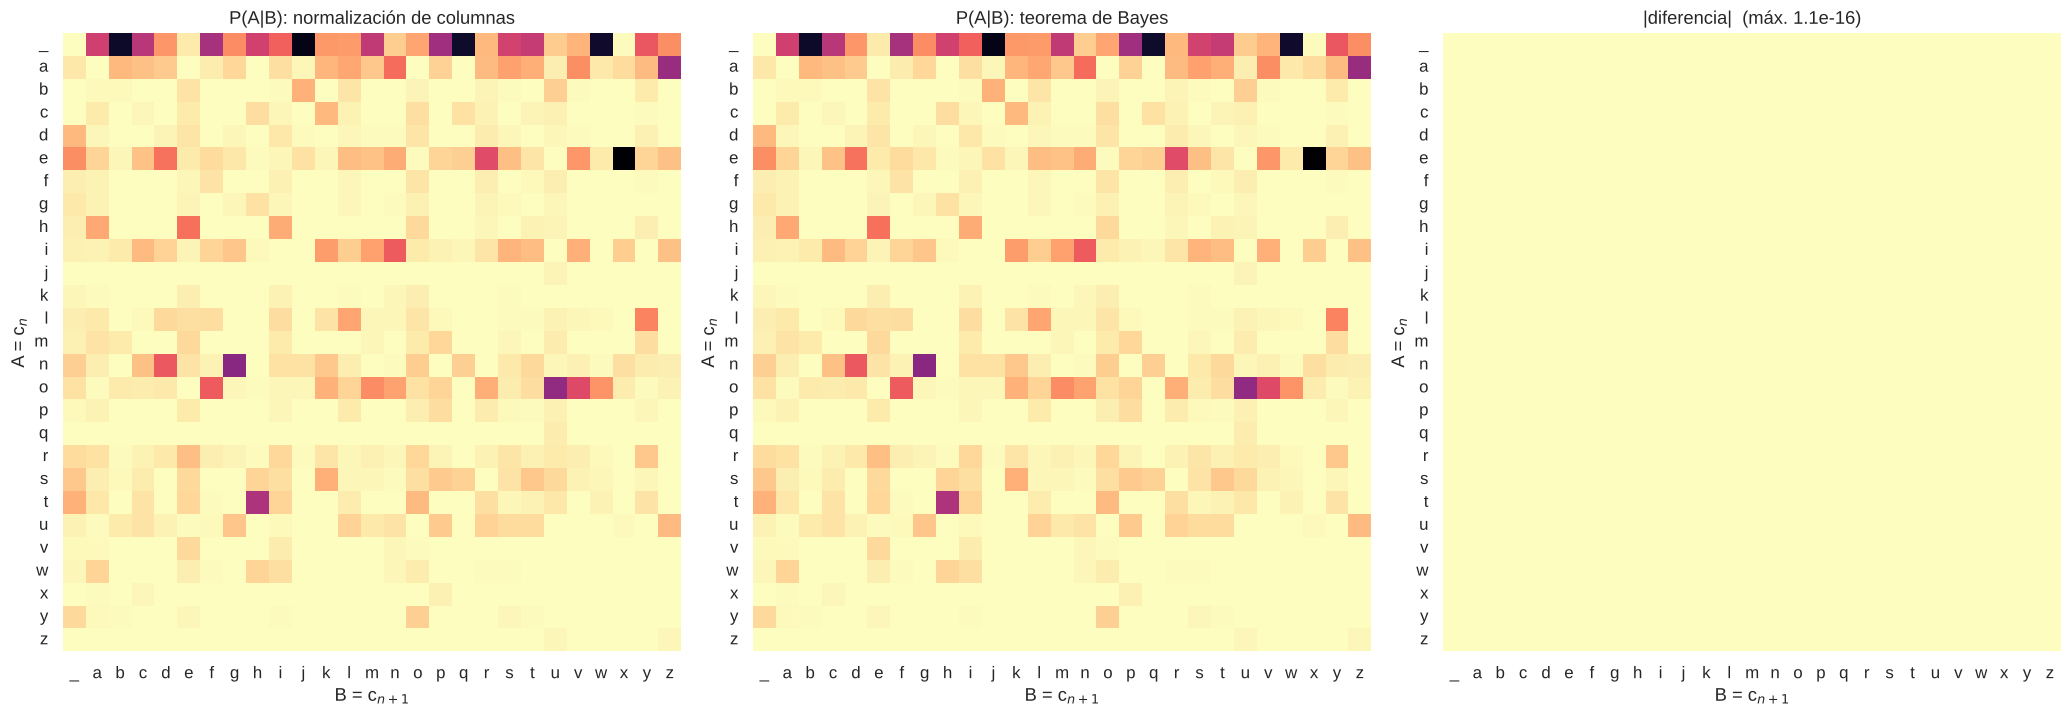

P(A|B) directa == P(A|B) por Bayes:       True
P(B|A)P(A) == P(A|B)P(B) == J (celdas):   True


In [15]:
J = CONT / CONT.sum()          # distribución conjunta de pares (A, B)
p_A = J.sum(axis=1)            # P(A)
p_B = J.sum(axis=0)            # P(B)

def dividir(num, den):
    den = np.broadcast_to(den, num.shape)
    return np.divide(num, den, out=np.zeros_like(num), where=den > 0)

atras_directo = dividir(J, p_B[None, :])                        # normalización de columnas
atras_bayes   = dividir(P * p_A[:, None], p_B[None, :])         # P(B|A) P(A) / P(B)
diferencia    = np.abs(atras_directo - atras_bayes)

fig, axes = plt.subplots(1, 3, figsize=(19, 6.3))
for ax, M, titulo in zip(axes, [atras_directo, atras_bayes, diferencia],
                         ["P(A|B): normalización de columnas", "P(A|B): teorema de Bayes",
                          f"|diferencia|  (máx. {diferencia.max():.1e})"]):
    sns.heatmap(M, cmap="magma_r", vmin=0, vmax=atras_directo.max(), square=True, cbar=False, ax=ax,
                xticklabels=ETIQ, yticklabels=ETIQ)
    ax.set(title=titulo, xlabel="B = c$_{n+1}$", ylabel="A = c$_n$")
    plt.setp(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

print("P(A|B) directa == P(A|B) por Bayes:      ", np.allclose(atras_directo, atras_bayes))
print("P(B|A)P(A) == P(A|B)P(B) == J (celdas):  ",
      np.allclose(P * p_A[:, None], atras_directo * p_B[None, :]) and np.allclose(P * p_A[:, None], J))

Las dos direcciones no son simétricas. Para $c=\text{«e»}$:

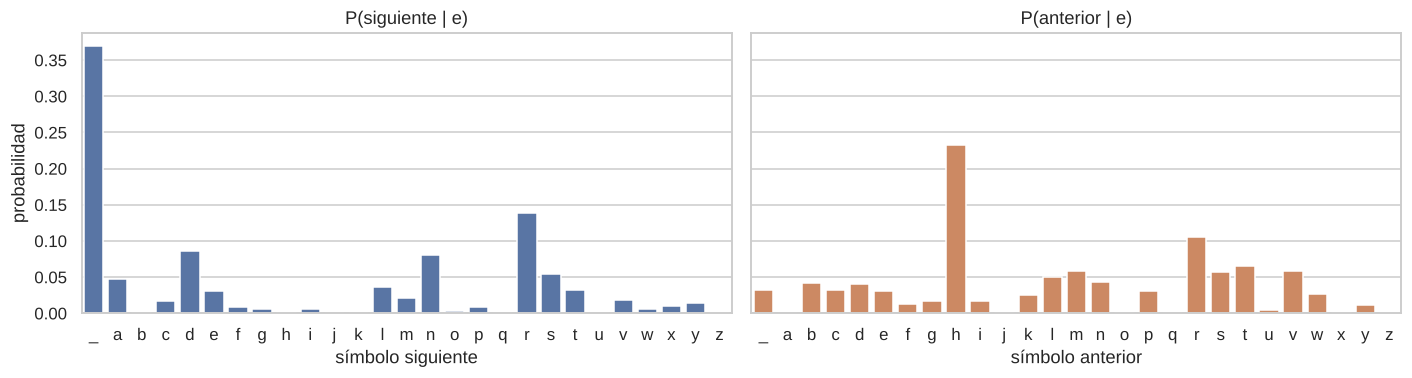

In [16]:
c = "e" if "e" in IDX else ALFABETO[1]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
sns.barplot(x=ETIQ, y=P[IDX[c]], color="#4c72b0", ax=axes[0])
axes[0].set(title=f"P(siguiente | {c})", xlabel="símbolo siguiente", ylabel="probabilidad")
sns.barplot(x=ETIQ, y=atras_directo[:, IDX[c]], color="#dd8452", ax=axes[1])
axes[1].set(title=f"P(anterior | {c})", xlabel="símbolo anterior")
plt.tight_layout(); plt.show()

### Validación fuera de muestra

La igualdad anterior es una identidad algebraica de $J$: se cumple para cualquier tabla de conteos. Para una verificación empírica se estiman las probabilidades solo con el 90 % inicial del texto (con suavizado $\alpha=0.1$) y se evalúa la dirección inversa sobre pares $(c_n, c_{n+1})$ del 10 % final. Se compara $\hat P(c_n\mid c_{n+1})$ obtenida con Bayes frente a la marginal $\hat P(c_n)$ (sin usar $c_{n+1}$), medidas por entropía cruzada. Además, por la regla de la cadena, $H(c_{n+1}\mid c_n)-H(c_n\mid c_{n+1})=H(c_{n+1})-H(c_n)$, que se verifica sobre la distribución conjunta estimada.

In [17]:
ALFA_B = 0.1
C_tr = np.zeros((N, N))
np.add.at(C_tr, (V[:corte - 1], V[1:corte]), 1)                  # pares del entrenamiento

J_tr = (C_tr + ALFA_B) / (C_tr + ALFA_B).sum()
pA_tr, pB_tr = J_tr.sum(axis=1), J_tr.sum(axis=0)
P_adelante = J_tr / pA_tr[:, None]                                # P(B|A)
R_bayes    = P_adelante * pA_tr[:, None] / pB_tr[None, :]         # P(A|B) por Bayes
R_directa  = J_tr / pB_tr[None, :]                                # P(A|B) por columnas
assert np.allclose(R_bayes, R_directa)

a_test, b_test = V[corte:-1], V[corte + 1:]                       # pares no vistos
H_bayes  = -np.log2(R_bayes[a_test, b_test]).mean()               # P(A|B)
H_previa = -np.log2(pA_tr[a_test]).mean()                         # P(A), sin usar B
H_adel   = -np.log2(P_adelante[a_test, b_test]).mean()            # P(B|A)

print(f"Entropía cruzada de prueba (bits):  P(A|B) por Bayes = {H_bayes:.3f}  |  P(A) sola = {H_previa:.3f}")
print(f"Dirección directa P(B|A) = {H_adel:.3f}  |  P(B) sola = {-np.log2(pB_tr[b_test]).mean():.3f}")

def H_cond(Jm, eje):
    p = Jm / Jm.sum(); marg = p.sum(axis=eje)
    return -(p * np.log2(p / np.expand_dims(marg, eje))).sum()
H_AB, H_BA = H_cond(J_tr, 1), H_cond(J_tr, 0)                    # H(B|A), H(A|B)
H_A = -(pA_tr * np.log2(pA_tr)).sum(); H_B = -(pB_tr * np.log2(pB_tr)).sum()
print(f"H(B|A) − H(A|B) = {H_AB - H_BA:.6f}  |  H(B) − H(A) = {H_B - H_A:.6f}")

Entropía cruzada de prueba (bits):  P(A|B) por Bayes = 3.309  |  P(A) sola = 4.074
Dirección directa P(B|A) = 3.309  |  P(B) sola = 4.074
H(B|A) − H(A|B) = -0.000002  |  H(B) − H(A) = -0.000002


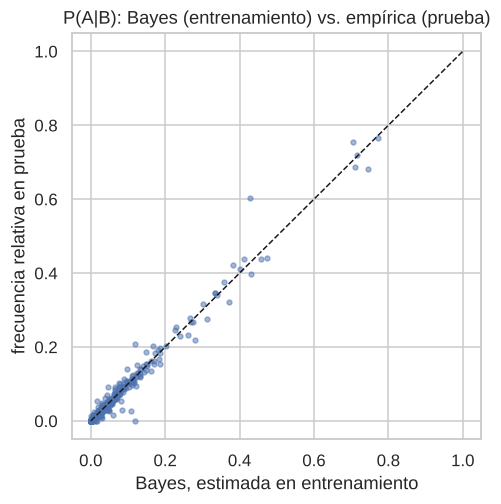

In [18]:
C_te = np.zeros((N, N))
np.add.at(C_te, (a_test, b_test), 1)
R_emp = dividir(C_te, C_te.sum(axis=0, keepdims=True))            # P(A|B) empírica en prueba
peso  = C_te.sum(axis=0) > 50                                     # columnas con muestra suficiente

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.scatter(R_bayes[:, peso].ravel(), R_emp[:, peso].ravel(), s=10, alpha=0.5, color="#4c72b0")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(title="P(A|B): Bayes (entrenamiento) vs. empírica (prueba)",
       xlabel="Bayes, estimada en entrenamiento", ylabel="frecuencia relativa en prueba")
plt.show()

## 5. Descomposición en valores singulares

$$P=U\Sigma V^{\top}=\sum_k \sigma_k\,u_k v_k^{\top}$$

Los $\sigma_k$, en orden descendente, ponderan componentes de rango uno: $u_k$ actúa sobre el símbolo actual y $v_k$ sobre el siguiente. Por el teorema de Eckart–Young, la truncación a rango $r$ minimiza el error de Frobenius entre las aproximaciones de rango $r$.

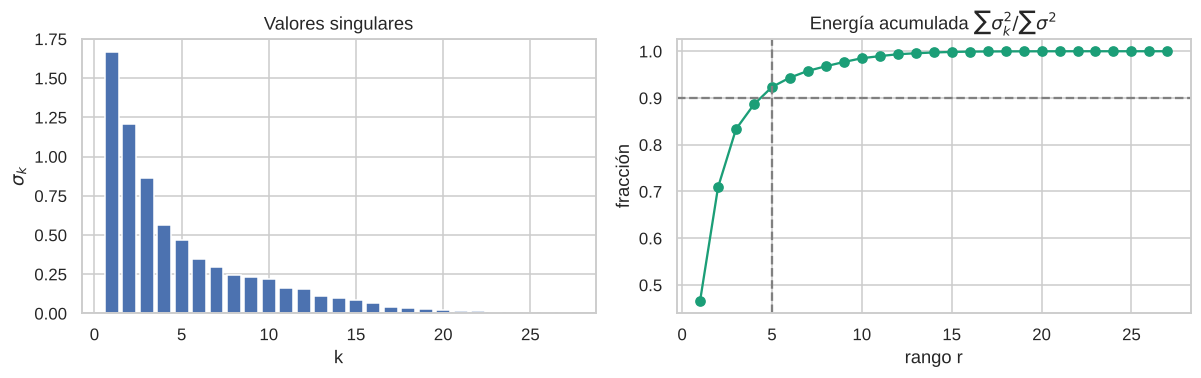

r = 5 de 27 componentes retienen el 90 % de la energía.


In [19]:
U, S, Vt = np.linalg.svd(P)
energia = S**2 / np.sum(S**2)
acumulada = np.cumsum(energia)
k90 = int(np.searchsorted(acumulada, 0.90) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(range(1, N + 1), S, color="#4c72b0")
axes[0].set(title="Valores singulares", xlabel="k", ylabel="$\\sigma_k$")
axes[1].plot(range(1, N + 1), acumulada, "o-", color="#1b9e77")
axes[1].axhline(0.9, color="gray", ls="--"); axes[1].axvline(k90, color="gray", ls="--")
axes[1].set(title="Energía acumulada $\\sum\\sigma_k^2 / \\sum\\sigma^2$", xlabel="rango r", ylabel="fracción")
plt.tight_layout(); plt.show()

print(f"r = {k90} de {N} componentes retienen el 90 % de la energía.")

### Aproximación de rango $r$

Error relativo $\lVert P-P_r\rVert_F/\lVert P\rVert_F$.

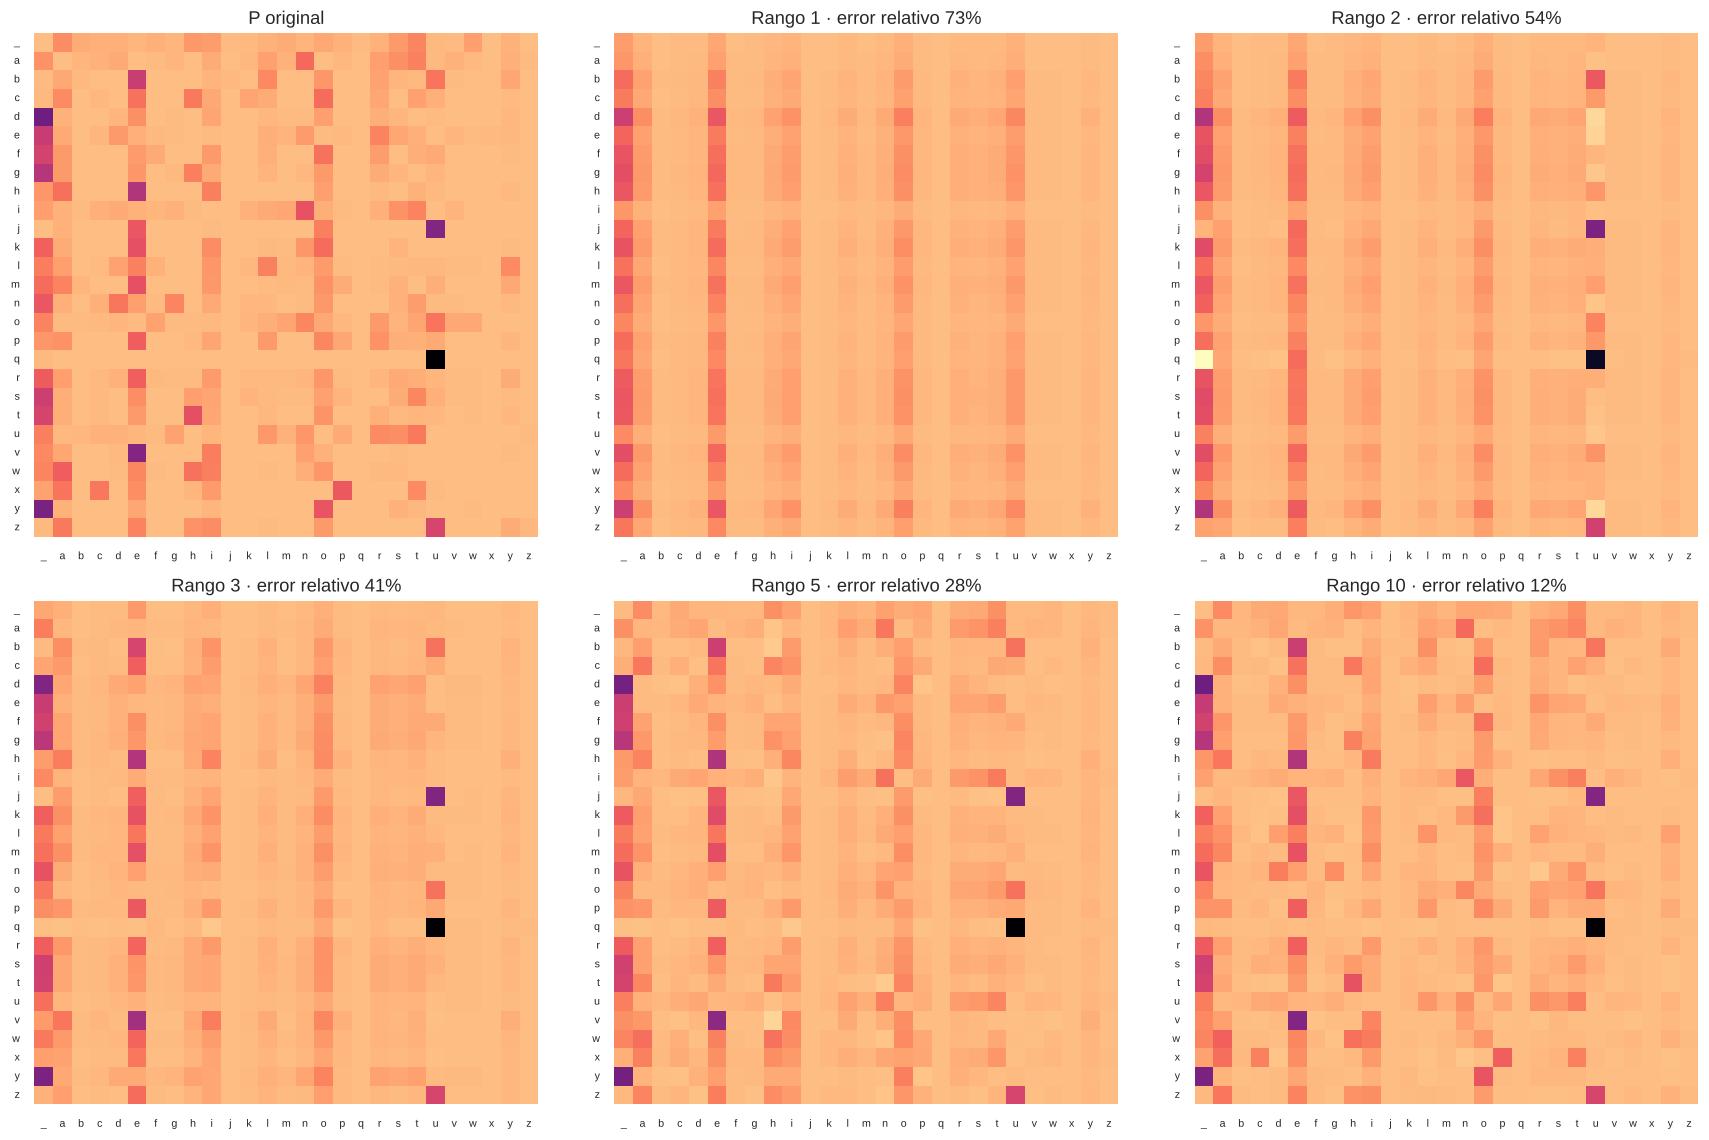

In [20]:
ks = [k for k in (1, 2, 3, 5, 10) if k < N]

def reconstruir(k):
    return (U[:, :k] * S[:k]) @ Vt[:k]

aproximaciones = [("P original", P)] + [(f"Rango {k}", reconstruir(k)) for k in ks]
vmin = min(A.min() for _, A in aproximaciones)

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for ax, (titulo, A) in zip(axes.ravel(), aproximaciones):
    sns.heatmap(A, cmap="magma_r", vmin=vmin, vmax=P.max(), square=True, cbar=False, ax=ax,
                xticklabels=ETIQ, yticklabels=ETIQ)
    error = np.linalg.norm(P - A) / np.linalg.norm(P)
    ax.set_title(titulo if titulo == "P original" else f"{titulo} · error relativo {error:.0%}")
    ax.tick_params(labelsize=7); plt.setp(ax.get_yticklabels(), rotation=0)
for ax in axes.ravel()[len(aproximaciones):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Proyección de los símbolos en las componentes 2 y 3

Coordenadas $\sigma_k u_k$ (filas, símbolo actual) y $\sigma_k v_k$ (columnas, símbolo siguiente) para $k=2,3$. La componente 1 se omite: sin centrado, refleja principalmente el perfil medio de transición. El signo de cada eje es arbitrario.

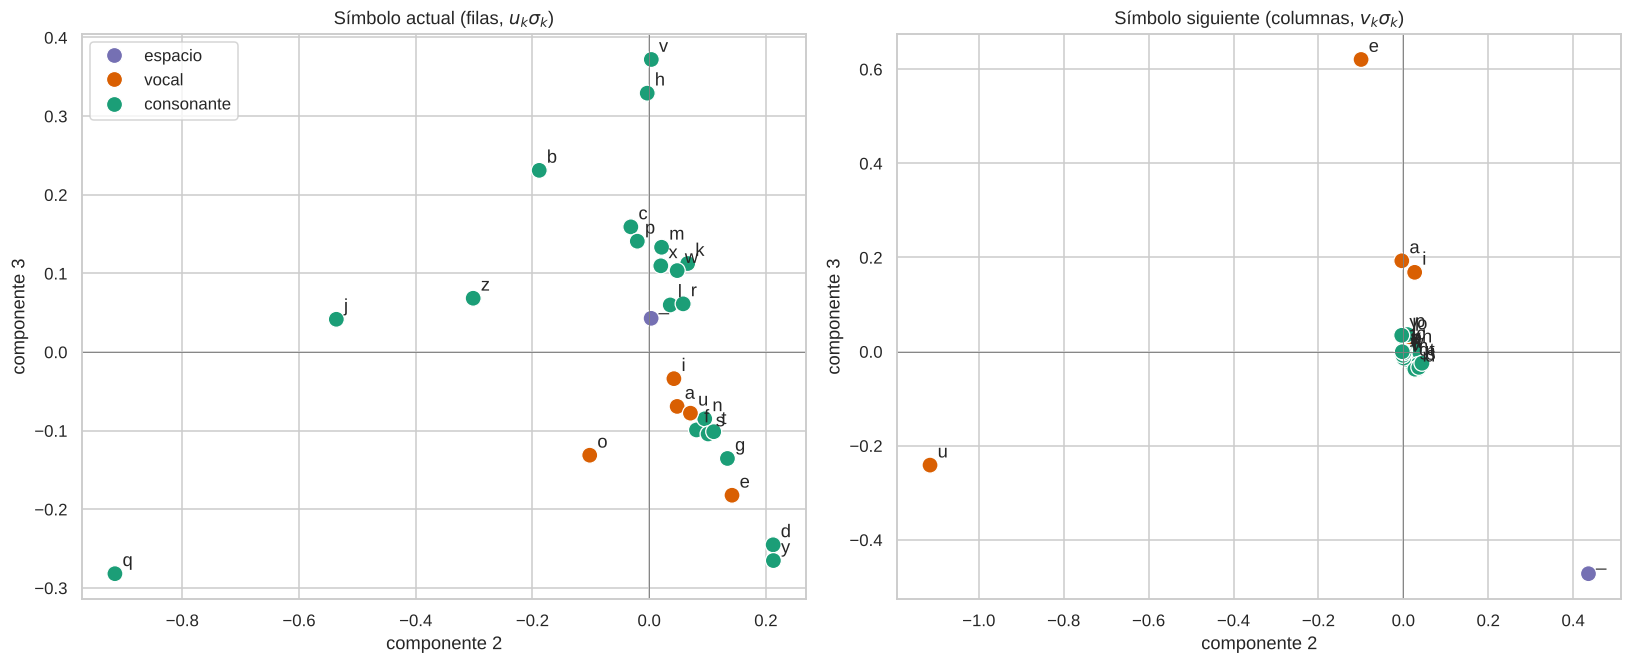

In [21]:
def clase(c):
    return "espacio" if c == " " else ("vocal" if c in "aeiou" else "consonante")

clases = [clase(c) for c in ALFABETO]
paleta = {"vocal": "#d95f02", "consonante": "#1b9e77", "espacio": "#7570b3"}

mapa_filas    = U[:, 1:3] * S[1:3]
mapa_columnas = Vt.T[:, 1:3] * S[1:3]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, xy, titulo in zip(axes, [mapa_filas, mapa_columnas],
                          ["Símbolo actual (filas, $u_k\\sigma_k$)", "Símbolo siguiente (columnas, $v_k\\sigma_k$)"]):
    sns.scatterplot(x=xy[:, 0], y=xy[:, 1], hue=clases, palette=paleta, s=110, ax=ax, legend=(ax is axes[0]))
    for (x, y), e in zip(xy, ETIQ):
        ax.annotate(e, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=12)
    ax.axhline(0, color="gray", lw=.6); ax.axvline(0, color="gray", lw=.6)
    ax.set(title=titulo, xlabel="componente 2", ylabel="componente 3")
plt.tight_layout(); plt.show()

### Distribución estacionaria

Vector $\pi$ con $\pi P=\pi$ (vector propio izquierdo, $\lambda=1$), comparado con la marginal empírica $p(c)$.

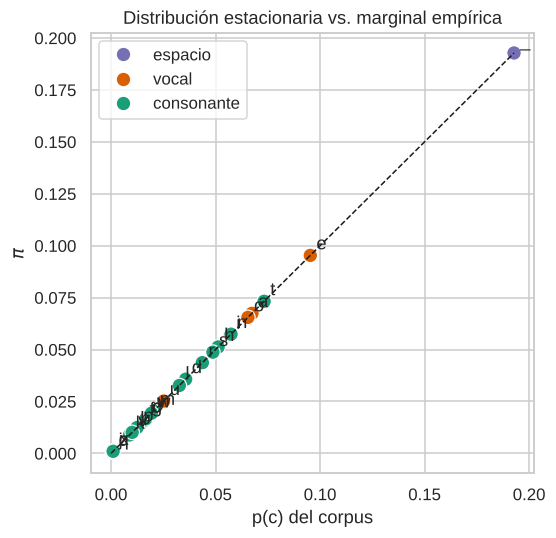

Mayor valor propio de P: 1.0000 | máx |π − p(c)| = 0.0000


In [22]:
valores, vectores = np.linalg.eig(P.T)
k = np.argmax(valores.real)
equilibrio = np.abs(vectores[:, k].real)
equilibrio /= equilibrio.sum()

fig, ax = plt.subplots(figsize=(5.2, 5.2))
sns.scatterplot(x=FREC, y=equilibrio, hue=clases, palette=paleta, s=90, ax=ax)
for x, y, e in zip(FREC, equilibrio, ETIQ):
    ax.annotate(e, (x, y), xytext=(4, 4), textcoords="offset points")
ax.plot([0, FREC.max()], [0, FREC.max()], "k--", lw=1)
ax.set(title="Distribución estacionaria vs. marginal empírica", xlabel="p(c) del corpus", ylabel="$\\pi$")
plt.show()

print(f"Mayor valor propio de P: {valores.real[k]:.4f} | máx |π − p(c)| = {np.abs(equilibrio - FREC).max():.4f}")

## 6. Extensión: contexto de orden $k$

Generalización a $P(c_{n+1}\mid c_{n-k+1},\dots,c_n)$, estimada por conteo con suavizado aditivo $\alpha=0.1$ y retroceso al contexto observado más largo cuando el contexto no aparece en el entrenamiento. Se usa la partición de la sección 2 (90 % entrenamiento, 10 % prueba). Métricas: entropía cruzada de prueba $H=-\tfrac1T\sum\log_2 P(c_{n+1}\mid\cdot)$, acierto top-2 y fracción de palabras generadas (20 000 símbolos) presentes en el vocabulario. $k=0$ equivale al generador 0b y $k=1$ a la matriz $P$.

In [23]:
K_MAX, ALPHA = 5, 0.1

def entrenar(texto, k_max):
    tablas = [defaultdict(Counter) for _ in range(k_max + 1)]
    for k, tabla in enumerate(tablas):
        for i in range(k, len(texto)):
            tabla[texto[i - k:i]][texto[i]] += 1
    totales = [{ctx: sum(c.values()) for ctx, c in t.items()} for t in tablas]
    return tablas, totales

def contexto(tablas, historial, k):
    """Contexto observado más largo (hasta orden k) al final del historial."""
    for j in range(min(k, len(historial)), -1, -1):
        ctx = historial[len(historial) - j:]
        if ctx in tablas[j]:
            return j, ctx

def evaluar(tablas, totales, k, texto, corte):
    bits = aciertos = 0.0
    for i in range(corte, len(texto)):
        j, ctx = contexto(tablas, texto[max(0, i - k):i], k)
        cnt, tot = tablas[j][ctx], totales[j][ctx]
        bits -= math.log2((cnt.get(texto[i], 0) + ALPHA) / (tot + ALPHA * N))
        aciertos += texto[i] in [c for c, _ in cnt.most_common(2)]
    T = len(texto) - corte
    return bits / T, aciertos / T

def generar_k(tablas, k, n, semilla):
    rnd = random.Random(semilla)
    salida = [rnd.choice(ALFABETO[1:])]
    while len(salida) < n:
        j, ctx = contexto(tablas, "".join(salida[-k:]) if k else "", k)
        cnt = tablas[j][ctx]
        salida.append(rnd.choices(list(cnt), weights=list(cnt.values()))[0])
    return "".join(salida)

tablas, totales = entrenar(TEXTO[:corte], K_MAX)

filas, muestras = [], {}
for k in range(K_MAX + 1):
    H, acc = evaluar(tablas, totales, k, TEXTO, corte)
    gen = generar_k(tablas, k, 20_000, SEMILLA)
    muestras[k] = gen[:200]
    filas.append({"k": k, "entropía cruzada (bits)": H, "acierto top-2": acc,
                  "palabras válidas": np.mean([p in VOCAB for p in gen.split()])})
res = pd.DataFrame(filas)
res.round(3)

,k,entropía cruzada (bits),acierto top-2,palabras válidas
0,0,4.074,0.292,0.214
1,1,3.309,0.439,0.305
2,2,2.626,0.581,0.436
3,3,2.081,0.691,0.710
4,4,1.855,0.738,0.890
5,5,1.851,0.748,0.974


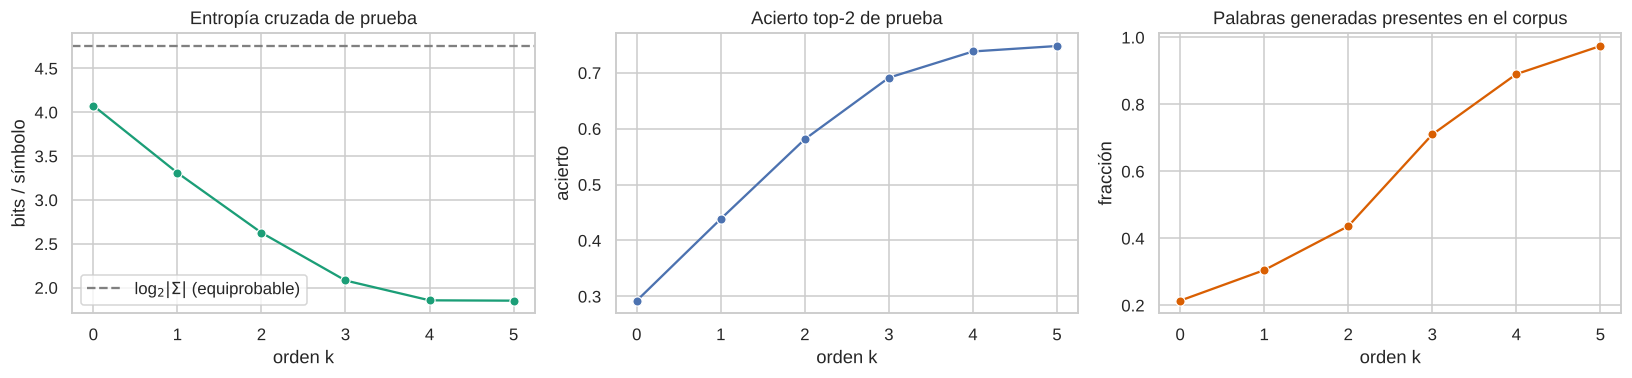

[k = 1]
kounloft aco ayad ay fis wethit as hedevne bloura hioncinorerous or thir win inouct
thechent girpent be lind he idomolthened fle w wese f hts a y t ry he neaicelolece well r
d onghu sts omave s sm ain

[k = 2]
kolkin mat the land but not mad had i sill as wers the lew sup a knovice posille he shem
the frey and s but ittlem a na the bund anses theyes throushosithis novicupt they yought
aguld a itip the yould

[k = 3]
kolnikolnikov turn in a rom and he ther he foung convinced at a lost interina again t are
finded he shed to had tal dignifice previlya when and rasked he know ther he i know and
through your day race

[k = 4]
kolnikodim for not a sort and you seeing of his box his mind of it all be bendid
raskolnikov wasn t belong to send i never he gard heart offician an into no and have the
died out svidrigaily can nasta

[k = 5]
kolnikov and died his lips his fist dounia he had complain him he was to have action what
do your sisted from they do the insinuations the only know he c

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
sns.lineplot(data=res, x="k", y="entropía cruzada (bits)", marker="o", color="#1b9e77", ax=axes[0])
axes[0].axhline(math.log2(N), color="gray", ls="--", label="log$_2|\\Sigma|$ (equiprobable)")
axes[0].legend(); axes[0].set(title="Entropía cruzada de prueba", ylabel="bits / símbolo")
sns.lineplot(data=res, x="k", y="acierto top-2", marker="o", color="#4c72b0", ax=axes[1])
axes[1].set(title="Acierto top-2 de prueba", ylabel="acierto")
sns.lineplot(data=res, x="k", y="palabras válidas", marker="o", color="#d95f02", ax=axes[2])
axes[2].set(title="Palabras generadas presentes en el corpus", ylabel="fracción")
for ax in axes: ax.set_xticks(range(K_MAX + 1)); ax.set_xlabel("orden k")
plt.tight_layout(); plt.show()

for k in range(1, K_MAX + 1):
    print(f"[k = {k}]\n{textwrap.fill(muestras[k], 90)}\n")

### Memorización frente a generalización

Una fracción alta de palabras válidas puede deberse a copia literal del entrenamiento. Se mide la fracción de ventanas de 12 símbolos del texto generado que aparecen textualmente en el 90 % de entrenamiento.

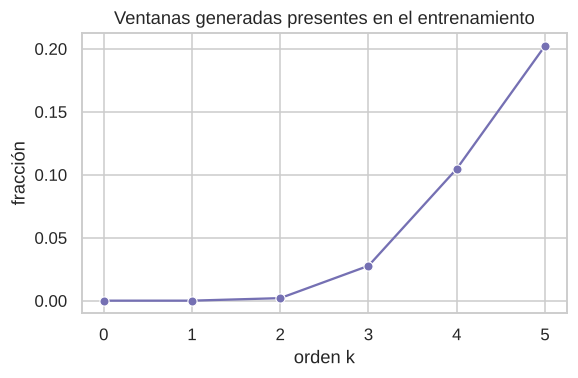

,k,entropía cruzada (bits),acierto top-2,palabras válidas,copia literal (12 símbolos)
0,0,4.074,0.292,0.214,0.000
1,1,3.309,0.439,0.305,0.000
2,2,2.626,0.581,0.436,0.002
3,3,2.081,0.691,0.710,0.028
4,4,1.855,0.738,0.890,0.105
5,5,1.851,0.748,0.974,0.202


In [25]:
VENT = 12
vistas = {TEXTO[i:i + VENT] for i in range(corte - VENT)}
copia = []
for k in range(K_MAX + 1):
    g = generar_k(tablas, k, 20_000, SEMILLA)
    copia.append(np.mean([g[i:i + VENT] in vistas for i in range(len(g) - VENT)]))
res["copia literal (12 símbolos)"] = copia

fig, ax = plt.subplots(figsize=(5.5, 3.6))
sns.lineplot(data=res, x="k", y="copia literal (12 símbolos)", marker="o", color="#7570b3", ax=ax)
ax.set(title="Ventanas generadas presentes en el entrenamiento", ylabel="fracción", xlabel="orden k",
       xticks=range(K_MAX + 1))
plt.tight_layout(); plt.show()
res.round(3)

## Conclusiones

1. $P(c_{n+1}\mid c_n)$ estimada por conteo supera a las líneas base de predicción top-$k$ (sección 2).
2. La generación de primer orden reproduce $p(c)$ y las transiciones; la validez léxica está limitada por el contexto de un solo símbolo (sección 3).
3. El teorema de Bayes se verifica numéricamente sobre $P$ dentro de la precisión de punto flotante (sección 4); al ser una identidad algebraica de $J$, se añade una validación con datos no vistos y la igualdad de entropías $H(B\mid A)-H(A\mid B)=H(B)-H(A)$.
4. La SVD indica que $P$ es aproximable con pocas componentes y agrupa los símbolos según su comportamiento de transición; el vector propio con $\lambda=1$ recupera la marginal (sección 5).
5. La sección 6 cuantifica el efecto del orden del contexto sobre la entropía cruzada, el acierto top-2, la validez léxica y la copia literal del entrenamiento.